In [ ]:
import matplotlib.pyplot as plt


In [4]:
import pandas as pd
from sklearn import linear_model
df = pd.read_excel("Analytics_mindset_case_study_solutions_Trinas_Trinkets.xlsx")


In [5]:
df.info()
df["InvoiceMonth"] = pd.to_datetime(df["InvoiceDate"]).dt.month


<class 'pandas.DataFrame'>
RangeIndex: 394829 entries, 0 to 394828
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   TransactionID          394829 non-null  int64         
 1   InvoiceNo              394829 non-null  object        
 2   StockCode              394829 non-null  object        
 3   Quantity               394829 non-null  int64         
 4   UnitPrice              394829 non-null  float64       
 5   CustomerNumber         394829 non-null  int64         
 6   ZipCode                394829 non-null  int64         
 7   State                  394829 non-null  str           
 8   City                   394829 non-null  str           
 9   Revenue                394829 non-null  float64       
 10  SalesTaxOwed           394829 non-null  float64       
 11  InvoiceDate            394829 non-null  datetime64[us]
 12  InvoiceYear            394829 non-null  int64         


/Users/salihozturk/Intro To Data Analytics/Data/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/salihozturk/Intro To Data Analytics/Data/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/salihozturk/Intro To Data Analytics/Data/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/salihozturk/Intro To Data Analytics/Data/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/salihozturk/Intro To Data Analytics/Data/.venv/lib/py

Text(0.5, 1.0, 'Comparison between the prognosted actual profit and the profit if there was a nexus')

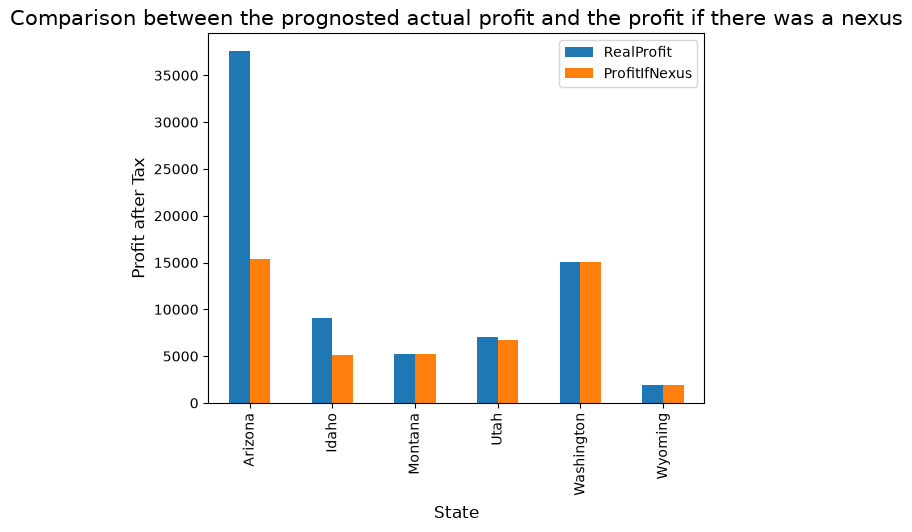

In [6]:
df["ProfitIfNexus"] = df["Profit"]-df["SalesTaxNoNexus"]
df["RealProfit"] = df["Profit"] - df["SalesTaxOwed"]
df_grouped = df.groupby(by=["State", "InvoiceYear", "InvoiceMonth"])[["RealProfit", "ProfitIfNexus"]].sum().reset_index()

growth_trends = []

for state in df_grouped["State"].unique():
    df_state = df_grouped[df_grouped["State"] == state].copy()
    df_state["time"] = range(len(df_state))

    if len(df_state) > 1:
        model_real = linear_model.LinearRegression()
        model_real.fit(df_state[["time"]], df_state[["RealProfit"]])
        
        model_ifnexus = linear_model.LinearRegression()
        model_ifnexus.fit(df_state[["time"]], df_state[["ProfitIfNexus"]])


        next_month_index = len(df_state)-1

        growth_trends.append({
            "State": state,
            "RealProfit": model_real.predict([[next_month_index]])[0][0],
            "ProfitIfNexus": model_ifnexus.predict([[next_month_index]])[0][0]
        })
df_trends = pd.DataFrame(growth_trends)
#df_trends = df_trends.sort_values(by="Prediction", ascending = False)
df_trends


df_trends.plot(kind="bar",x="State", y=["RealProfit", "ProfitIfNexus"])

plt.xlabel("State", fontsize =12)
plt.ylabel("Profit after Tax", fontsize = 12)
plt.title("Comparison between the prognosted actual profit and the profit if there was a nexus", fontsize =15)



                                             


